# 🛡️ Machine Learning for Network Intrusion Detection

**Goal:** build classifiers that detect **malicious network connections** (attacks) vs normal traffic.

**Data:** the **NSL-KDD** benchmark dataset, an improved version of KDD Cup 99. Each row is one network connection with 41 features (duration, protocol, bytes sent, failed logins, error rates…). The official test set contains **attack types that never appear in training**, which makes it a realistic test of generalisation.

**Models:** Logistic Regression, Decision Tree, Random Forest.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

sns.set_theme(style="whitegrid")
import os
os.makedirs("images", exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 1. Load the data

In [2]:
cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent",
"hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations",
"num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count",
"serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
"srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
"dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
"dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

BASE = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/"
train = pd.read_csv(BASE + "KDDTrain+.txt", names=cols)
test = pd.read_csv(BASE + "KDDTest+.txt", names=cols)
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 2. Explore
The raw labels are specific attack names. I group them into the 4 standard families: **DoS** (denial of service), **Probe** (scanning), **R2L** (remote-to-local access), **U2R** (privilege escalation).

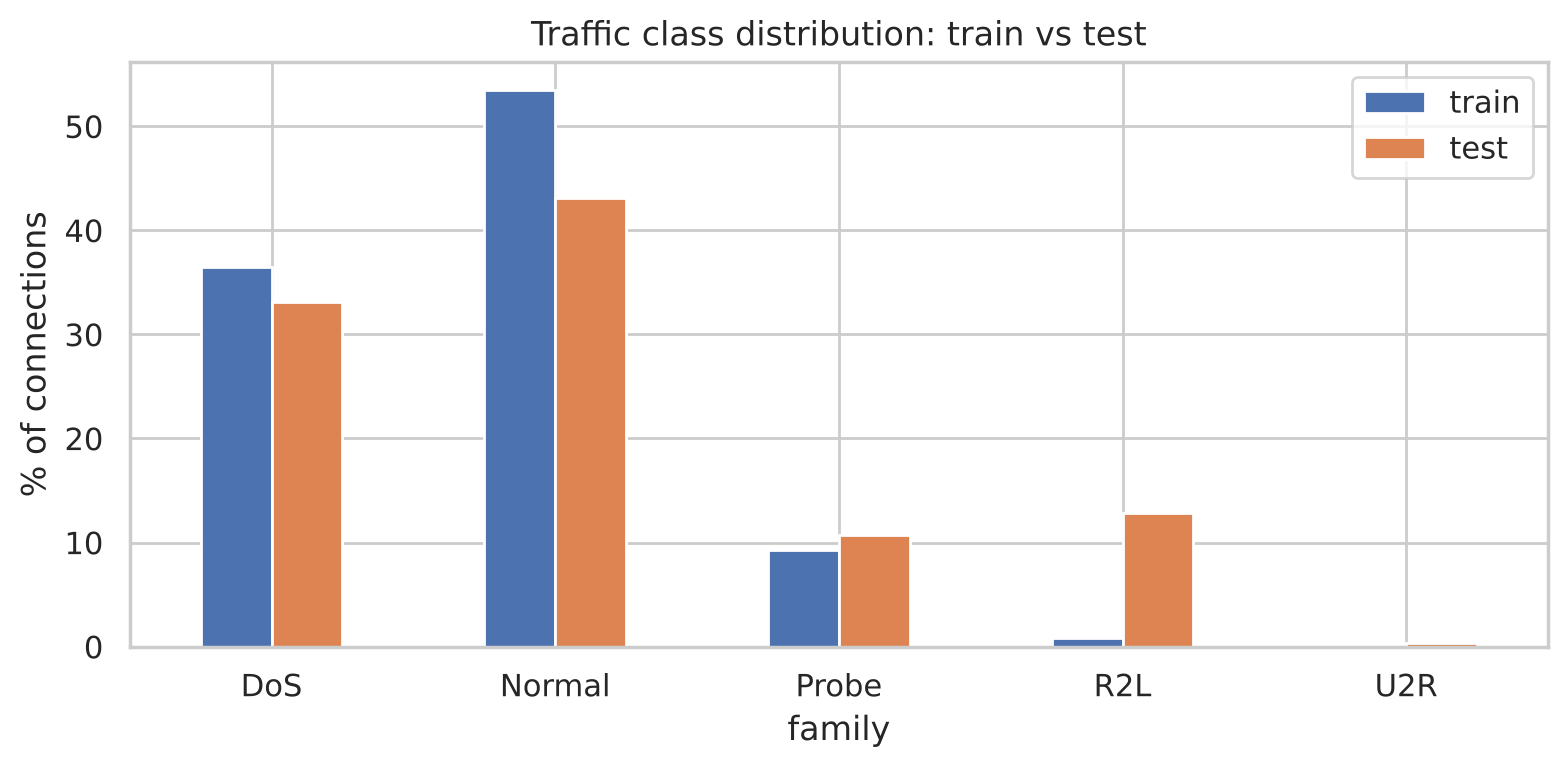

,train,test
family,,
DoS,36.5,33.1
Normal,53.5,43.1
Probe,9.3,10.7
R2L,0.8,12.8
U2R,0.0,0.3


In [3]:
families = {
 "DoS":   ["back","land","neptune","pod","smurf","teardrop","apache2","mailbomb","processtable","udpstorm"],
 "Probe": ["ipsweep","nmap","portsweep","satan","mscan","saint"],
 "R2L":   ["ftp_write","guess_passwd","imap","multihop","phf","spy","warezclient","warezmaster","named",
           "sendmail","snmpgetattack","snmpguess","worm","xlock","xsnoop","httptunnel"],
 "U2R":   ["buffer_overflow","loadmodule","perl","rootkit","ps","sqlattack","xterm"]}
lookup = {a: fam for fam, attacks in families.items() for a in attacks}
for df in (train, test):
    df["family"] = df["label"].map(lambda l: "Normal" if l == "normal" else lookup.get(l, "Other"))
    df["is_attack"] = (df["label"] != "normal").astype(int)

dist = pd.DataFrame({"train": train["family"].value_counts(normalize=True),
                     "test": test["family"].value_counts(normalize=True)}).mul(100).round(1)
dist.plot(kind="bar", figsize=(8, 4), rot=0, color=["#4C72B0", "#DD8452"])
plt.ylabel("% of connections"); plt.title("Traffic class distribution: train vs test")
savefig("class_distribution")
dist

In [4]:
unseen = set(test["label"]) - set(train["label"])
share = test["label"].isin(unseen).mean()
print(f"{len(unseen)} attack types appear ONLY in the test set → {share:.1%} of test rows")
print(sorted(unseen))

17 attack types appear ONLY in the test set → 16.6% of test rows
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


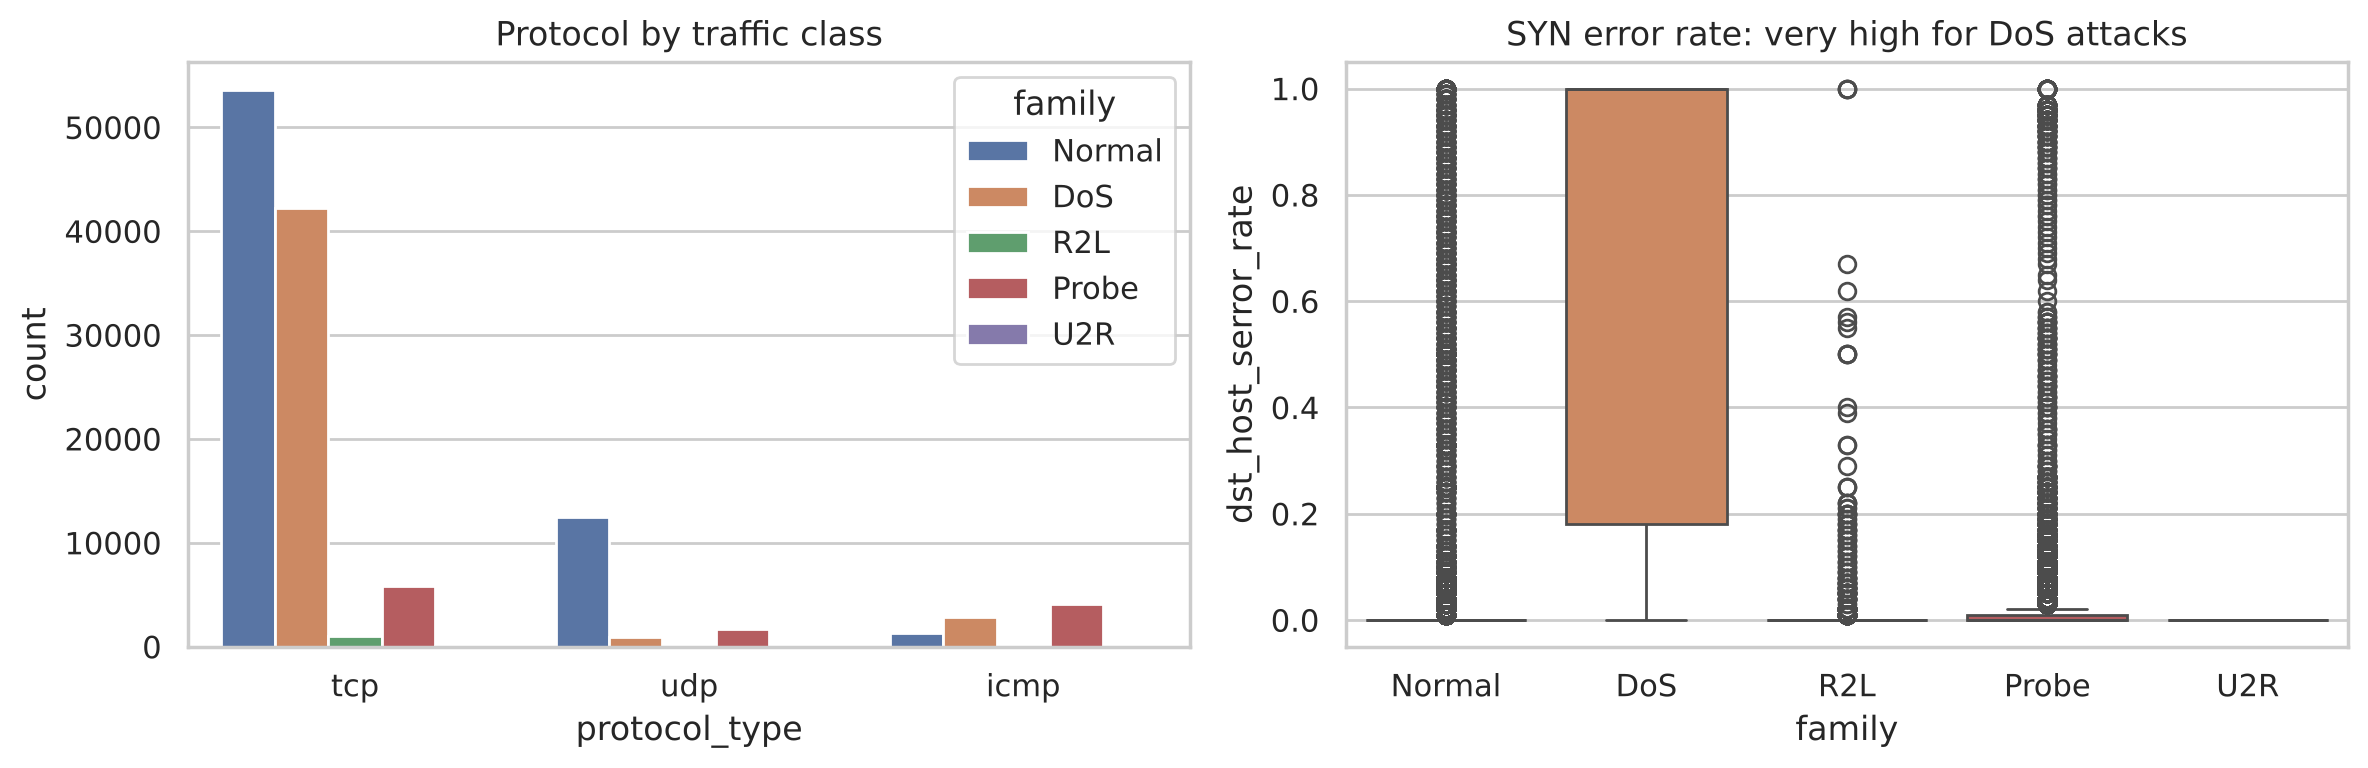

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train, x="protocol_type", hue="family", ax=axes[0])
axes[0].set_title("Protocol by traffic class")
sns.boxplot(data=train, x="family", y="dst_host_serror_rate", ax=axes[1], hue="family", legend=False)
axes[1].set_title("SYN error rate: very high for DoS attacks")
savefig("feature_exploration")

## 3. Preprocess
- 3 categorical features (`protocol_type`, `service`, `flag`) → one-hot encoding
- numeric features → standardisation (needed for logistic regression)
- Using a `Pipeline` means the encoder and scaler are fitted **only on training data**.

In [6]:
cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in cols if c not in cat_cols + ["label", "difficulty"]]

X_train, y_train = train[cat_cols + num_cols], train["is_attack"]
X_test, y_test = test[cat_cols + num_cols], test["is_attack"]

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)])

## 4. Train and compare models (binary: attack vs normal)

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)}

rows, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", prep), ("clf", clf)]).fit(X_train, y_train)
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall (detection rate)": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall (detection rate),F1,ROC-AUC
model,,,,,
Logistic Regression,0.754,0.918,0.624,0.743,0.792
Decision Tree,0.784,0.967,0.643,0.772,0.773
Random Forest,0.779,0.969,0.632,0.765,0.962


**Reading the metrics:** in security, **recall** (how many attacks we catch) matters most, because a missed attack is far more costly than a false alarm. Precision tells us how many alarms are real.

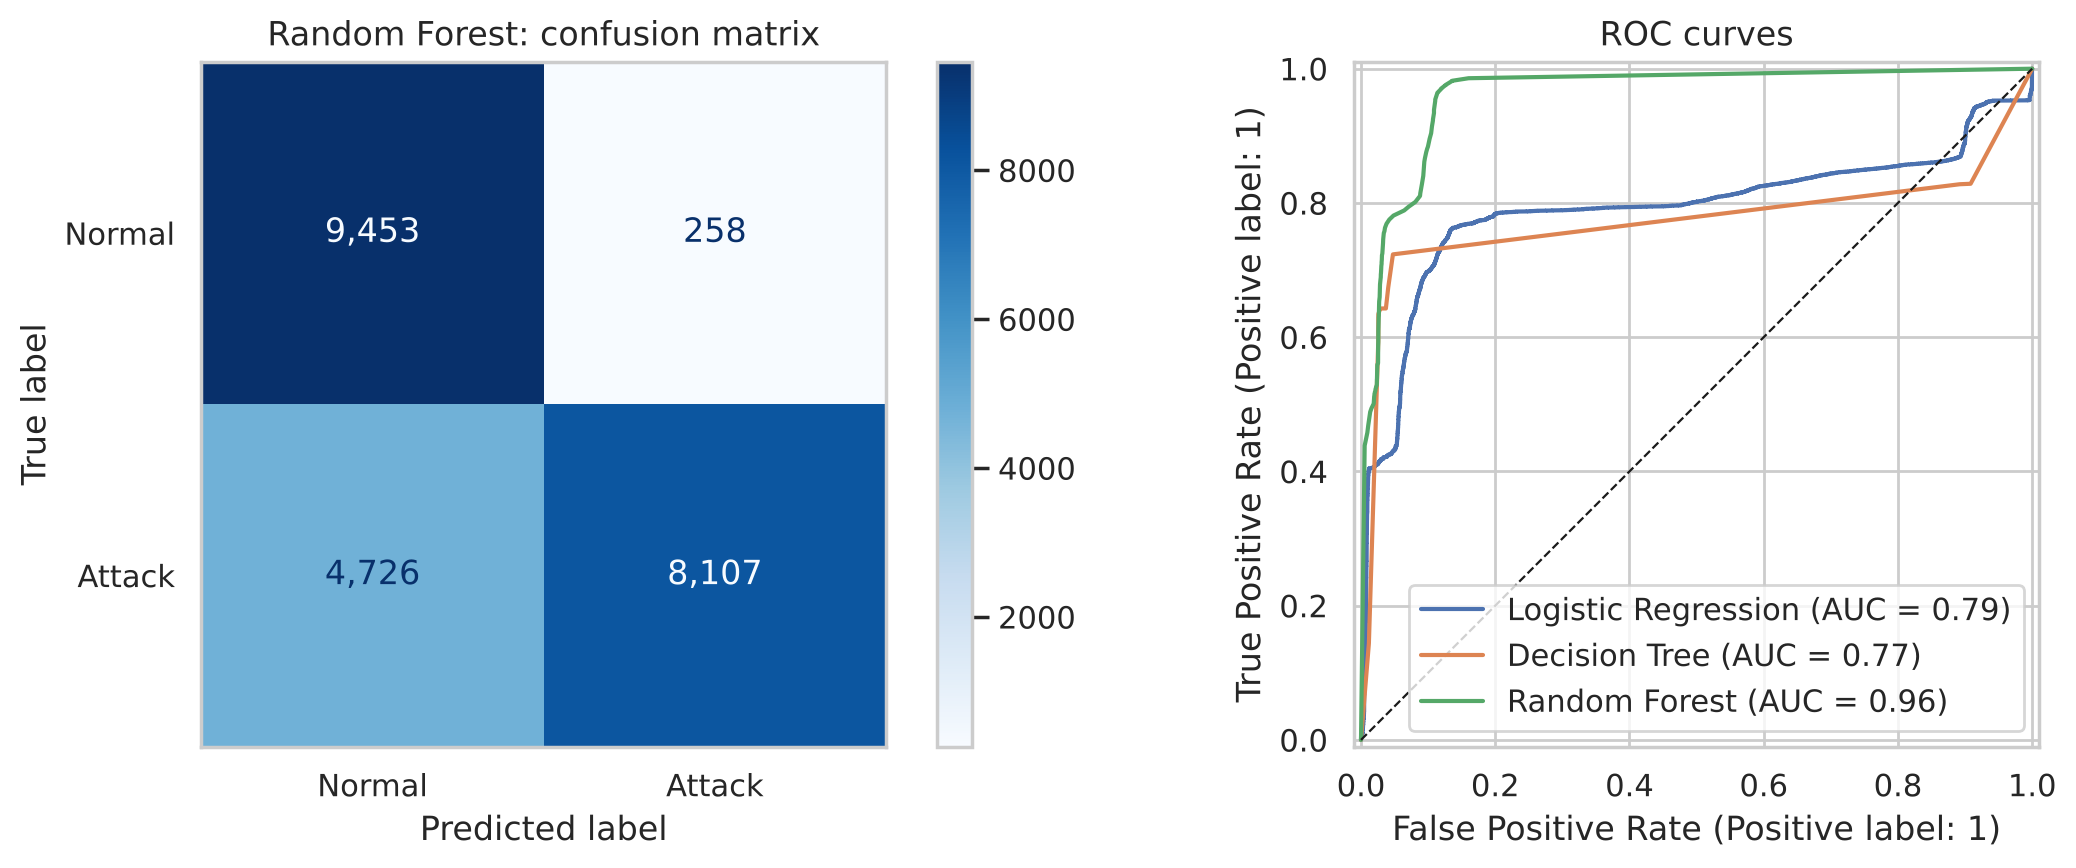

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
best = fitted["Random Forest"]
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["Normal", "Attack"],
                                      cmap="Blues", values_format=",", ax=axes[0])
axes[0].set_title("Random Forest: confusion matrix"); axes[0].grid(False)
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=.8); axes[1].set_title("ROC curves")
savefig("confusion_roc")

## 5. Which attacks are hard to detect?

In [9]:
test["rf_pred"] = best.predict(X_test)
by_family = (test[test["is_attack"] == 1].groupby("family")["rf_pred"].mean().mul(100).round(1)
             .rename("detection rate %").to_frame())
by_family

,detection rate %
family,
DoS,82.6
Probe,73.5
R2L,5.6
U2R,13.4


In [10]:
test["unseen_type"] = test["label"].isin(unseen)
test[test["is_attack"] == 1].groupby("unseen_type")["rf_pred"].mean().mul(100).round(1).rename(
    "detection rate %").rename(index={False: "attack type seen in training", True: "NEW attack type"})

unseen_type
attack type seen in training    77.0
NEW attack type                 29.8
Name: detection rate %, dtype: float64

**Insight:** DoS and Probe attacks are caught reliably, but R2L/U2R attacks, especially **new attack types**, are often missed. This is the core weakness of supervised (signature-like) detection, and the reason real systems add **anomaly detection** for unknown attacks.

## 6. Feature importance

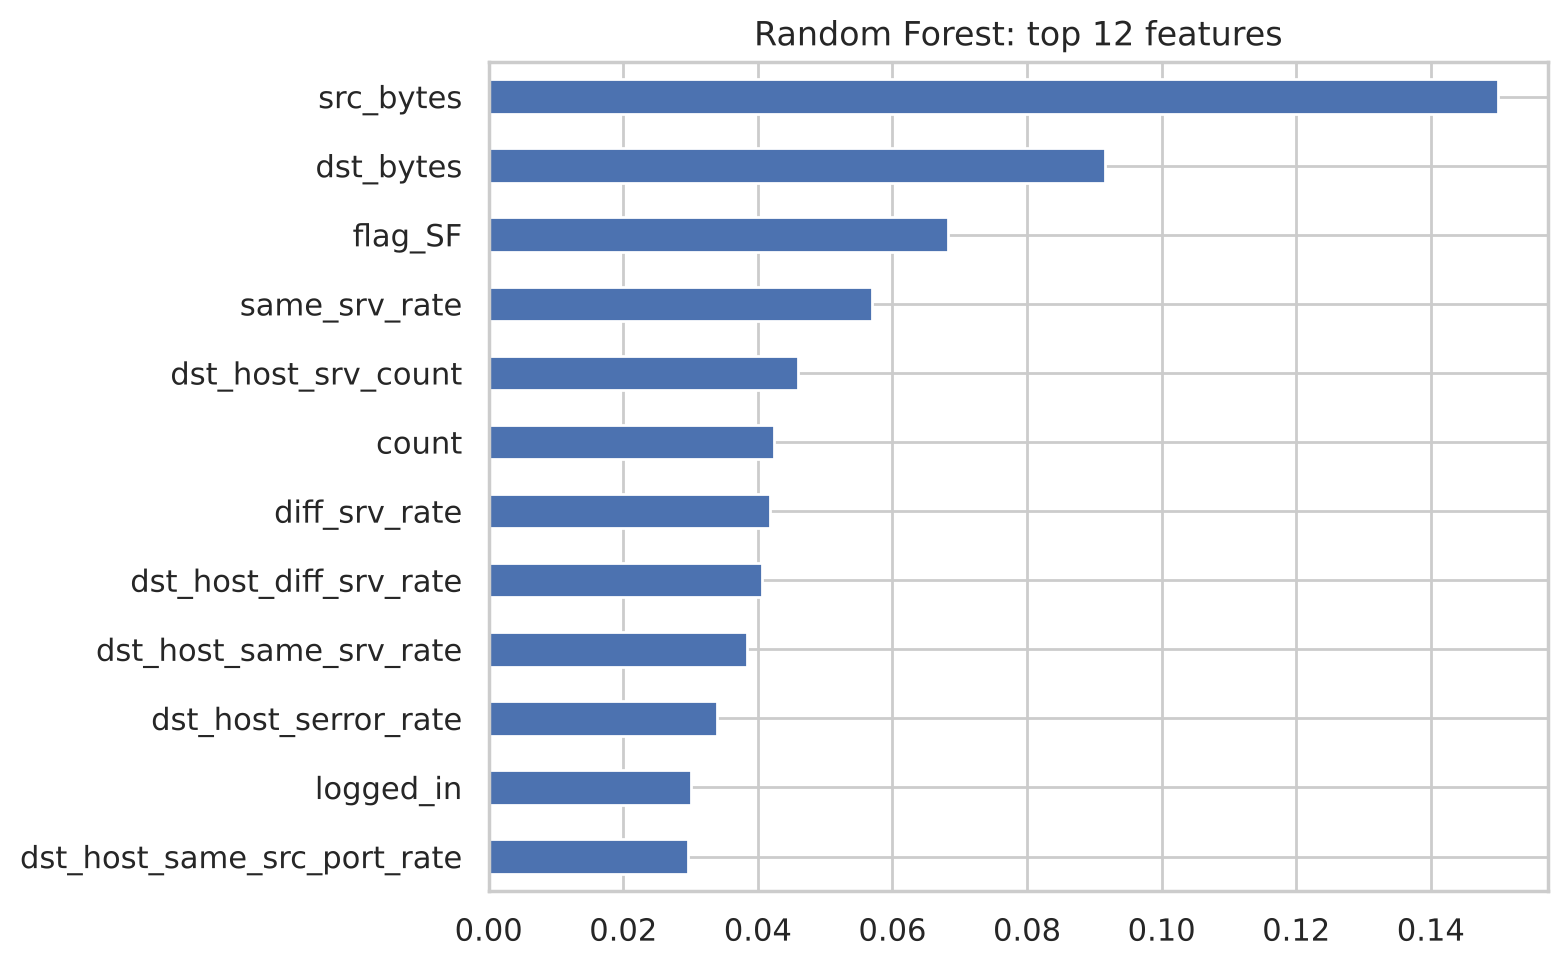

In [11]:
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["clf"].feature_importances_, index=names)
imp.index = imp.index.str.replace("num__", "").str.replace("cat__", "")
imp.sort_values().tail(12).plot(kind="barh", figsize=(8, 5), color="#4C72B0")
plt.title("Random Forest: top 12 features")
savefig("feature_importance")

## Conclusions

- Tree-based models beat logistic regression; **Random Forest** has by far the best ROC-AUC (0.96), meaning it ranks attacks above normal traffic very well. When it raises an alarm it is right ~97 % of the time.
- Test accuracy (~75–78 %) and recall (~63 %) are much lower than on training data because 1 in 6 test rows are **attack types never seen during training**: new attack types are detected only ~30 % of the time vs ~77 % for known ones. An honest, realistic result.
- The most important features (bytes sent, error rates, connection counts, service type) match how attacks behave in practice: e.g. DoS floods create many half-open connections (high SYN error rate).

**Next steps:** tune the decision threshold for higher recall, try gradient boosting (XGBoost/LightGBM), and add an unsupervised anomaly detector (Isolation Forest, autoencoder) to catch novel attacks.

**Skills shown:** handling categorical data, ML pipelines without leakage, choosing metrics for imbalanced/security problems, model comparison and error analysis.